# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

https://github.com/inarbut/time-series-final

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [3]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "Narbut"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [4]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [5]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [6]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

### 2.1 What is in the series
Hourly generation of a mixed portfolio: a strong daytime hump (solar) on top of a night floor of ~170 that moves with wind. Below: the daily profile, the annual cycle, and correlations with the weather.

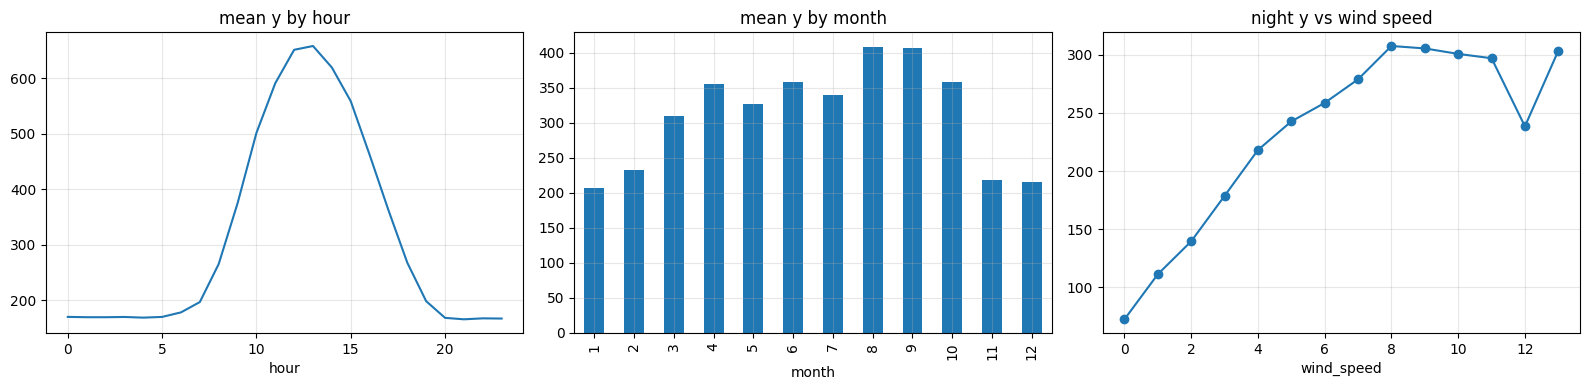

y              1.00
cloud_cover    0.16
temperature    0.28
wind_speed     0.30
pressure      -0.02
humidity      -0.38
daylight       0.39
air_density   -0.26
Name: y, dtype: float64

In [7]:
import lightgbm as lgb   # pip install lightgbm
d = data.assign(hour=data.ds.dt.hour, month=data.ds.dt.month)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
d.groupby("hour").y.mean().plot(ax=ax[0], title="mean y by hour")
d.groupby("month").y.mean().plot(ax=ax[1], kind="bar", title="mean y by month")
night = d[d.daylight == 0]
night.groupby("wind_speed").y.mean().plot(ax=ax[2], marker="o", title="night y vs wind speed")
plt.tight_layout(); plt.show()
data.drop(columns="ds").corr()["y"].round(2)

### 2.2 The model
LightGBM regression on calendar (hour, day of year, day of week, trend), weather (incl. `daylight*(1-cloud_cover)` as a solar proxy and `air_density*wind³` as a wind-power proxy). Two variants: with lags that are known for the whole 48h horizon (y 48h and 168h back), and without lags. Model A = the average of the two. Model B (below) adds the level at the forecast origin. The final forecast averages A and B.
For the horizon the model is fed `weather_forecast.csv`.

In [8]:
W = ["cloud_cover","temperature","wind_speed","pressure","humidity","daylight","air_density"]

def features(df, y_full):
    X = pd.DataFrame(index=df.index)
    X["hour"] = df.ds.dt.hour; X["doy"] = df.ds.dt.dayofyear; X["dow"] = df.ds.dt.dayofweek
    X["t"] = (df.ds - pd.Timestamp("2023-01-01")).dt.days
    for c in W: X[c] = df[c].values
    X["clear_day"] = df.daylight * (1 - df.cloud_cover)
    X["wind3"] = df.wind_speed ** 3 * df.air_density
    X["lag48"] = y_full.shift(48).values; X["lag168"] = y_full.shift(168).values
    X["roll48_mean"] = y_full.shift(48).rolling(24).mean().values
    return X

PARAMS = dict(objective="regression", learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_estimators=600, random_state=0)

def fit_predict(hist, future_weather, use_lags=True):
    full = pd.concat([hist, future_weather], ignore_index=True)
    X = features(full, full["y"])
    cols = [c for c in X.columns if use_lags or not c.startswith(("lag", "roll"))]
    n = len(hist)
    m = lgb.LGBMRegressor(**PARAMS).fit(X.iloc[200:n][cols], hist["y"].iloc[200:])
    return np.clip(m.predict(X.iloc[n:][cols]), 0, None)

# Model B: one model for all horizons. Each training row is (target hour, horizon h), with features known at
# the forecast origin: mean of the last 6/24/72 hours and the last value. This lets the forecast start from
# the current wind/solar regime instead of the long-run average for that hour and date.
def base_X(df):
    X = pd.DataFrame(index=df.index)
    X["hour"] = df.ds.dt.hour; X["doy"] = df.ds.dt.dayofyear
    for c in W: X[c] = df[c].values
    X["clear_day"] = df.daylight * (1 - df.cloud_cover); X["wind3"] = df.wind_speed ** 3 * df.air_density
    return X

def fit_predict_origin(hist, fut, hs=(1, 6, 12, 18, 24, 30, 36, 42, 48)):
    y = hist.y.values; Xb = base_X(hist); cs = np.cumsum(np.r_[0, y]); parts = []
    for h in hs:
        idx = np.arange(200, len(hist)); o = idx - h
        P = Xb.iloc[idx].copy(); P["h"] = h
        P["lvl24"] = (cs[o + 1] - cs[o - 23]) / 24; P["lvl6"] = (cs[o + 1] - cs[o - 5]) / 6
        P["lvl72"] = (cs[o + 1] - cs[np.maximum(o - 71, 0)]) / 72; P["last"] = y[o]
        P["target"] = y[idx]; parts.append(P)
    T = pd.concat(parts, ignore_index=True); cols = T.columns.drop("target")
    m = lgb.LGBMRegressor(**PARAMS).fit(T[cols], T.target)
    F = base_X(fut.reset_index(drop=True)); F["h"] = np.arange(1, len(fut) + 1)
    F["lvl24"], F["lvl6"], F["lvl72"], F["last"] = y[-24:].mean(), y[-6:].mean(), y[-72:].mean(), y[-1]
    return np.clip(m.predict(F[cols]), 0, None)

def final_forecast(hist, fut):
    # equal-weight combination: (A with lags + A without lags) / 2, averaged with B
    a = (fit_predict(hist, fut, True) + fit_predict(hist, fut, False)) / 2
    return (a + fit_predict_origin(hist, fut)) / 2, a

### 2.3 Validation: 60 rolling origins
Every 3rd midnight over the last ~6 months, forecast 48h ahead from the data before it, and score against seasonal naive. Caveat: the backtest uses the *actual* weather, while the real horizon uses a forecast whose errors grow on day 2, so these scores are optimistic. (~6 minutes.)

In [9]:
ORIGINS = 60
rows = []
for k in range(ORIGINS):
    e = len(data) - H - 3 * 24 * k
    hist, fut = data.iloc[:e], data.iloc[e:e + H]
    sn = snaive(hist.y.values)
    fw = fut.drop(columns="y")
    g1 = fit_predict(hist, fw, True); g0 = fit_predict(hist, fw, False); gb = fit_predict_origin(hist, fw)
    rows.append(pd.DataFrame({"origin": k, "step": np.arange(1, H + 1), "actual": fut.y.values,
                              "daylight": fut.daylight.values, "sn": sn[0], "sn_lo": sn[1], "sn_hi": sn[2],
                              "gbm_lags": g1, "gbm_nolags": g0, "A": (g1 + g0) / 2, "B": gb, "final": ((g1 + g0) / 2 + gb) / 2}))
bt = pd.concat(rows, ignore_index=True)

per = bt.groupby("origin").apply(lambda g: pd.Series(
    {f"{c} {m}": f(g.actual, g[c]) for c in ["sn", "gbm_lags", "gbm_nolags", "A", "B", "final"]
     for m, f in [("RMSE", rmse), ("MAPE", mape)]}))
print(per.mean().round(2).to_string())
print("origins where final beats snaive on RMSE:", int((per["final RMSE"] < per["sn RMSE"]).sum()), "of", ORIGINS)
print("same, last 10 origins (Sep-Oct):", int((per["final RMSE"] < per["sn RMSE"]).iloc[:10].sum()), "of 10")

sn RMSE            255.03
sn MAPE            133.86
gbm_lags RMSE      213.31
gbm_lags MAPE      105.89
gbm_nolags RMSE    207.63
gbm_nolags MAPE    102.04
A RMSE             205.44
A MAPE             103.08
B RMSE             213.11
B MAPE              74.69
final RMSE         199.62
final MAPE          87.66
origins where final beats snaive on RMSE: 47 of 60
same, last 10 origins (Sep-Oct): 8 of 10


### 2.4 The 95% interval: split-conformal by group
Errors differ by time of day (night, morning ramp, midday peak, evening ramp, late evening) and between day 1 and day 2, so the radius is the 95th percentile of |error| within each (time of day, day of horizon) group: 5 x 2 = 10 groups. An earlier version used only night/day x day 1/day 2 (Winkler about 1023 vs about 1010 with 5 parts of the day). Using only the most recent 10-30 windows' errors was worse (Winkler 1263-1353 vs 1201 on the last 20 windows), so all windows are used. Checked leave-one-origin-out: the radius for an origin uses the other 59 origins only.

In [10]:
def time_group(ds, step):
    # 5 parts of the day x day 1 / day 2 of the horizon
    part = pd.cut(pd.Series(ds).dt.hour.values, [-1, 5, 8, 15, 19, 23],
                  labels=["night", "morning", "midday", "evening", "late"]).astype(str)
    return pd.Series(part).values + "_day" + np.where(np.asarray(step) > 24, "2", "1")

bt["ds"] = np.concatenate([data.ds.iloc[len(data) - H - 3 * 24 * k: len(data) - 3 * 24 * k].values for k in range(ORIGINS)])
bt["group"] = time_group(bt.ds, bt.step)
bt.to_csv("backtest_results.csv", index=False)
bt["res"] = bt.actual - bt.final
C = 100                                     # offset so that night hours near zero do not get a zero radius
bt["rel"] = bt.res / (bt.final + C)

def radii(train, col="res"):
    return train.groupby("group")[col].apply(lambda r: np.quantile(np.abs(r), 0.95))

def bounds(g, train, recipe):
    if recipe == "absolute":
        r = g.group.map(radii(train)).values
    else:                                   # relative: radius grows with the forecast
        r = g.group.map(radii(train, "rel")).values * (g.final.values + C)
    return np.clip(g.final.values - r, 0, None), g.final.values + r

out = {}
for recipe in ["absolute", "relative"]:
    ws, cov = [], []
    for o, g in bt.groupby("origin"):
        lo, hi = bounds(g, bt[bt.origin != o], recipe)
        ws.append(winkler(g.actual, lo, hi)); cov.append(np.mean((g.actual >= lo) & (g.actual <= hi)))
    out[recipe] = {"Winkler": np.mean(ws), "coverage": np.mean(cov)}
sn_w = bt.groupby("origin").apply(lambda g: winkler(g.actual, g.sn_lo, g.sn_hi)).mean()
sn_c = bt.groupby("origin").apply(lambda g: np.mean((g.actual >= g.sn_lo) & (g.actual <= g.sn_hi))).mean()
out["snaive"] = {"Winkler": sn_w, "coverage": sn_c}
print(pd.DataFrame(out).T.round(3))
RECIPE = min(["absolute", "relative"], key=lambda k: out[k]["Winkler"])
print("chosen interval recipe:", RECIPE)

           Winkler  coverage
absolute  1026.194     0.945
relative  1129.449     0.944
snaive    1847.268     0.820
chosen interval recipe: absolute


### 2.5 The template's single validation window, next to the benchmark row

In [11]:
def make_interval(point, ds, train=bt):
    g = pd.DataFrame({"final": point, "group": time_group(ds, np.arange(1, H + 1))})
    return bounds(g, train, RECIPE)

w0 = bt[bt.origin == 0]                     # origin 0 is the template's validation window
results.loc["LightGBM combination + conformal"] = score(valid, w0.final, *make_interval(w0.final.values, w0.ds.values, bt[bt.origin != 0]))
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0
LightGBM combination + conformal,78.145,45.921,690.590,1.0


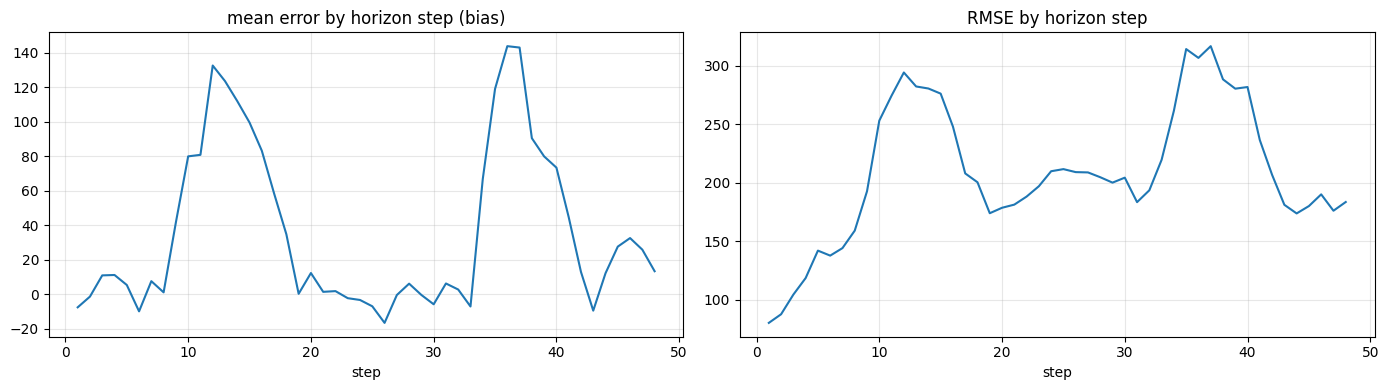

In [12]:
# residuals of the final approach on the backtest
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
bt.groupby("step").res.mean().plot(ax=ax[0], title="mean error by horizon step (bias)")
bt.groupby("step").res.apply(lambda r: np.sqrt(np.mean(r**2))).plot(ax=ax[1], title="RMSE by horizon step")
plt.tight_layout(); plt.show()

## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

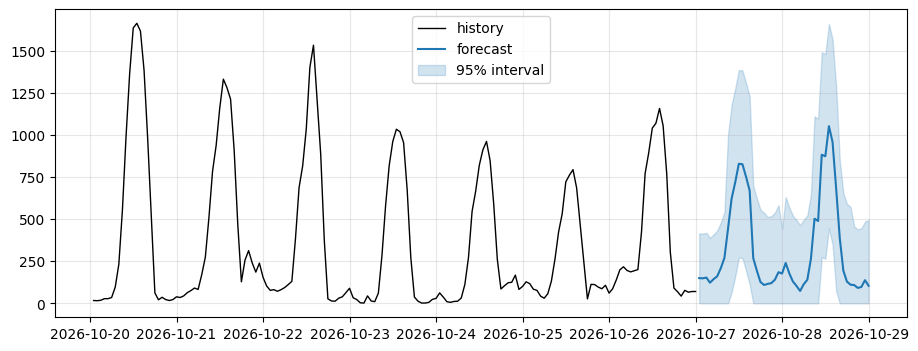

In [15]:
forecast, _ = final_forecast(data, weather_fc)
lower_95, upper_95 = make_interval(forecast, weather_fc.ds.values)

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [16]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved NARBUT_project.csv


Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.

AI usage: I used Claude to help design the model and the validation code; I reviewed, ran and can explain every step.